# Environment Setup

![image](./1a-dev-env.png){height=550}

In [1]:
import torch
import matplotlib.pyplot as plt
from IPython.display import clear_output
from sklearn.cluster import KMeans

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print(torch.cuda.current_device())
    print(torch.cuda.device_count())
    print(torch.cuda.get_device_name(0))

device

0
1
NVIDIA GeForce MX550


device(type='cuda', index=0)

# Simulation of Multivariate Normal Distribution


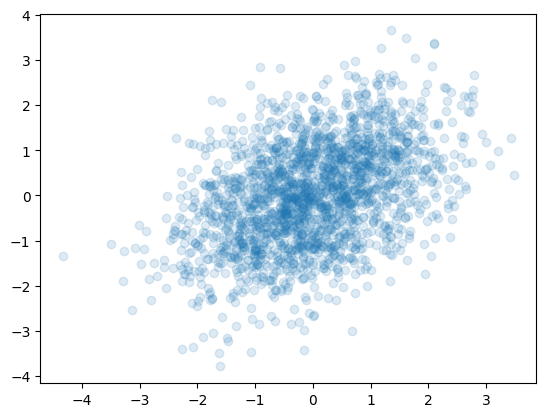

In [2]:

torch.random.manual_seed(42)

mean_A = torch.tensor([-0.5, -0.5])
covariance_A = torch.tensor([[1, 0.25], [0.25, 1]])

mean_B = torch.tensor([0.5, 0.5])
covariance_B = torch.tensor([[1, 0.25], [0.25, 1]])

m = 1000

dist_A = torch.distributions.MultivariateNormal(mean_A, covariance_A)
dist_B = torch.distributions.MultivariateNormal(mean_B, covariance_B)

samples_A = dist_A.sample((m,))
samples_B = dist_B.sample((m,))

x = torch.cat((samples_A, samples_B), dim=0)
x_np = x.numpy()
plt.scatter(x_np[:, 0], x_np[:, 1], alpha=0.15)
plt.show()


# K-mean Clustering

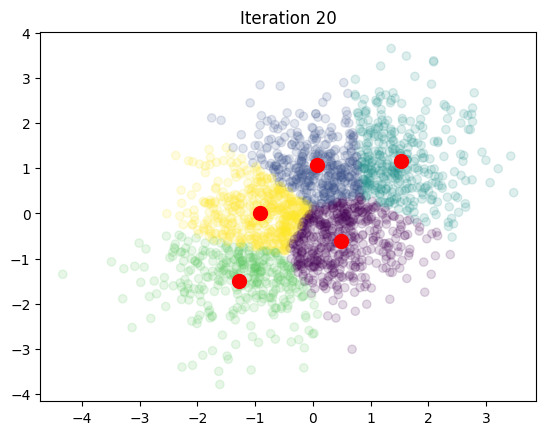

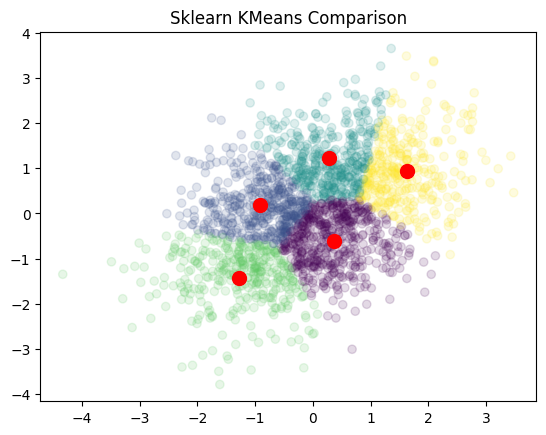

In [3]:
# Scale Data
#x = ((x-x.min()) / (x.max()-x.min())) * 9 +1
k = 5
max_iter = 1000

def random_centroids(x, k):
    indices = torch.randperm(x.size(0))[:k]
    centroids = x[indices]
    return centroids

def assign_clusters(x, centroids):
    distances = torch.cdist(x, centroids)
    distances = distances.min(dim=1)
    clusters = distances.indices
    return clusters


def plot_clusters(x, clusters, centroids, iteration = 0):
    x_clusters = x.clone()
    x_clusters = x_clusters.view(-1, 2)
    x_clusters = torch.cat((x_clusters, clusters.unsqueeze(1).float()), dim=1)
    clear_output(wait=True)
    plt.scatter(x_clusters[:, 0], x_clusters[:, 1], c=x_clusters[:, 2], alpha=0.15)
    plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=100)
    plt.title(f"Iteration {iteration}")
    plt.show()

def update_centroids(x, clusters, k):
    centroids = torch.zeros(k, 2)
    for i in range(k):
        mask = clusters == i
        cluster_points = x[mask]
        centroids[i] = cluster_points.mean(dim=0)
    return centroids


#Random Centroids
centroids = random_centroids(x, k)
#Assign Clusters
clusters = assign_clusters(x, centroids)
#Plot Clusters
plot_clusters(x, clusters, centroids)

for i in range(max_iter):
    old_centroids = torch.clone(centroids)
    centroids = update_centroids(x, clusters, k)
    if torch.all(centroids == old_centroids):
        break
    clusters = assign_clusters(x, centroids)
    plot_clusters(x, clusters, centroids, i)


#Compare with sklearn
kmeans = KMeans(n_clusters=k)
kmeans.fit(x)
centroids = kmeans.cluster_centers_
clusters = kmeans.labels_

plt.scatter(x_np[:, 0], x_np[:, 1], c=clusters, alpha=0.15)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=100)
plt.title("Sklearn KMeans Comparison")
plt.show()


# Projection with Principal Components Analysis (PCA)


PCA from scratch
 tensor([[-0.2172,  0.4827, -0.1778,  0.8296],
        [ 0.1181,  0.7996, -0.3097, -0.5007],
        [-0.8886, -0.1522, -0.3705, -0.2235],
        [-0.3863,  0.3232,  0.8574, -0.1054]])

Sklearn for comparison
 [[ 0.21718078  0.48266853 -0.17786908  0.82959399]
 [-0.11811316  0.79963564 -0.30969876 -0.50071829]
 [ 0.88860975 -0.15219097 -0.37047459 -0.22351553]
 [ 0.3863347   0.3231901   0.85743679 -0.10533667]]


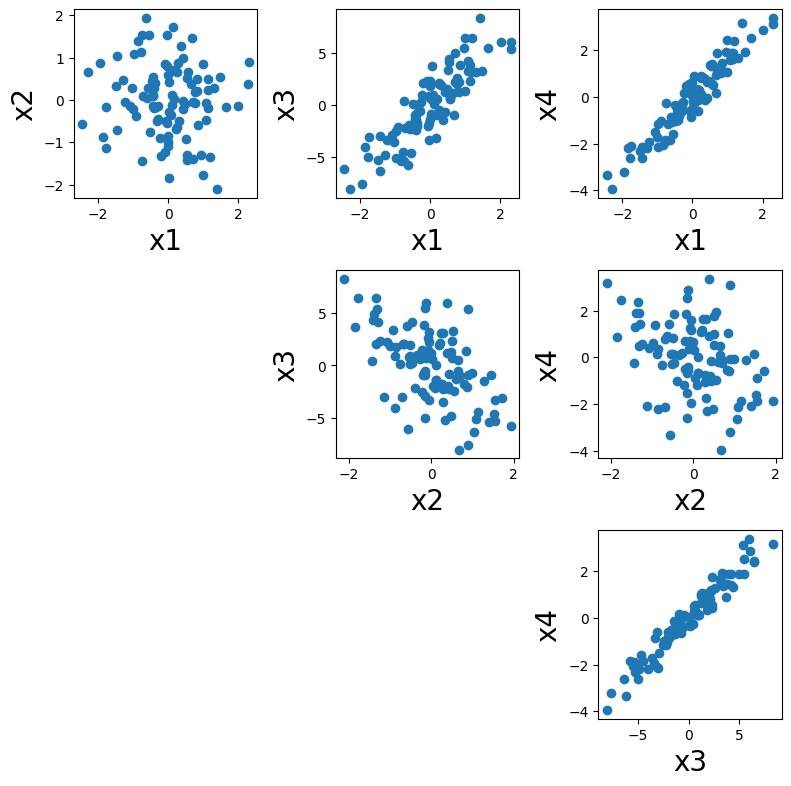

In [4]:
#generate some data
x = torch.normal(0, 1, size=(100, 4))

x[:, 2] = 3 * x[:, 0] - 2 * x[:, 1] + torch.normal(0, 0.1, size=(100,))
x[:, 3] = 1.5 * x[:, 0] - 0.5 * x[:, 1] + torch.normal(0, 0.1, size=(100,))

x = x - x.mean(dim=0)

plt.figure(figsize=(10,10))
x_np = x.cpu().numpy()
for i in range(4):
    for j in range(4):
        if j > i:
            plt.subplot(4,4,i*4+j+1)
            plt.scatter(x_np[:,i], x_np[:,j])
            plt.xlabel(f'x{i+1}', fontsize=20)
            plt.ylabel(f'x{j+1}', fontsize=20)
plt.tight_layout()

cov_matrix = torch.cov(x.T)

eigvals, eigvecs = torch.linalg.eigh(cov_matrix)

sorted_indices = torch.argsort(eigvals, descending=True)
principal_components = eigvecs[:, sorted_indices]
print("\nPCA from scratch\n",principal_components)

#Compare To sklearn
from sklearn.decomposition import PCA

#initialize
pca = PCA(n_components=4)

#fit
pca.fit(x)
PCA(n_components=4)
#get principal components
principal_comps_builtin = pca.components_.T
print("\nSklearn for comparison\n",principal_comps_builtin)


